<a href="https://colab.research.google.com/github/sebasarellano/Aprendizaje_Automatico/blob/main/01_Mi_segundo_modelo_Arellano.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/andres-merino/AprendizajeAutomaticoInicial-05-N0105/blob/main/2-Ejercicios/01-Mi-segundo-modelo-Plantilla.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<table style="border: none; border-collapse: collapse;">
    <tr>
        <td style="width: 20%; vertical-align: middle; padding-right: 10px;">
            <img src="https://i.imgur.com/nt7hloA.png" width="100">
        </td>
        <td style="width: 2px; text-align: center;">
            <font color="#0030A1" size="7">|</font><br>
            <font color="#0030A1" size="7">|</font>
        </td>
        <td>
            <p style="font-variant: small-caps;"><font color="#0030A1" size="5">
                <b>Facultad de Ciencias Exactas, Naturales y Ambientales</b>
            </font> </p>
            <p style="font-variant: small-caps;"><font color="#0030A1" size="4">
                Aprendizaje Automático Inicial &bull; Mi segundo modelo
            </font></p>
            <p style="font-style: oblique;"><font color="#0030A1" size="3">
                Sebastián Arellano &bull; 29/10/2026
            </font></p>
        </td>  
    </tr>
</table>

---
## <font color='264CC7'> Introducción </font>

Este cuaderno está diseñado para practicar el entrenamiento y evaluación de un modelo de regresión lineal utilizando datos reales. Los objetivos principales son:

- Entrenar un modelo de regresión lineal.
- Evaluar el ajuste del modelo.


Del conjunto de datos disponible [aquí](https://raw.githubusercontent.com/mGalarnyk/Tutorial_Data/master/King_County/kingCountyHouseData.csv), se desea predecir la variable `price` en función de las variables `bedrooms`, `bathrooms`, `sqft_living`, `sqft_lot`, `floors`.

In [ ]:
# Paquetes necesarios
import numpy as np  # Para generación de datos y operaciones numéricas
import pandas as pd  # Para manejo de datos estructurados
import matplotlib.pyplot as plt  # Para visualización de datos
from sklearn.linear_model import LinearRegression  # Para el modelo de regresión lineal
from sklearn.metrics import mean_squared_error, r2_score  # Para evaluación del modelo
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, KBinsDiscretizer, OneHotEncoder
from sklearn.decomposition import PCA

---
## <font color='264CC7'> Lectura de Datos </font>


Realiza la lectura de los datos y presenta las primeras filas del conjunto de datos.

In [ ]:
url= "https://raw.githubusercontent.com/mGalarnyk/Tutorial_Data/master/King_County/kingCountyHouseData.csv"
df = pd.read_csv(url)
df.head()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


---
## <font color='264CC7'> Características y etiquetas </font>

Separa las características y las etiquetas y mostrar la dimensión de cada elemento.

In [ ]:
# Selección de características (X) y etiqueta (y)
X = df[['bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors']]
y = df['price']

# Dimensión de cada elemento
print(f"Dimensión de X (características): {X.shape}")
print(f"Dimensión de y (etiqueta): {y.shape}")

Dimensión de X (características): (21613, 5)
Dimensión de y (etiqueta): (21613,)


---
## <font color='264CC7'> Conjunto de entrenamiento y prueba </font>

Divide los datos en dos conjuntos: uno para entrenamiento y otro para prueba y visualiza la dimensión de cada conjunto. Usar `random_state` igual al último número de tu cédula.

In [ ]:
# Dividir datos en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=2026)

Revisa la distribución de las etiquetas en los conjuntos de entrenamiento y prueba.

Entrenamiento:
mean    540650.891614
std     366528.734817
50%     450000.000000
Name: price, dtype: float64

Prueba:
mean    537837.402730
std     369545.113729
50%     452000.000000
Name: price, dtype: float64


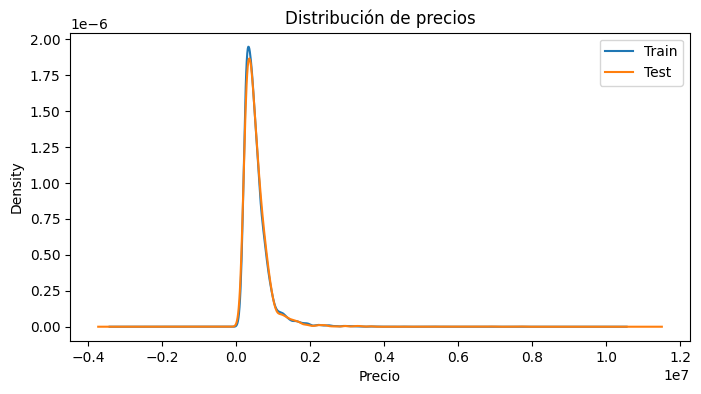

In [ ]:
# Estadísticas descriptivas básicas
print("Entrenamiento:")
print(y_train.describe()[['mean', 'std', '50%']])
print("\nPrueba:")
print(y_test.describe()[['mean', 'std', '50%']])

# Gráfico de densidad comparativo
plt.figure(figsize=(8, 4))
y_train.plot(kind='kde', label='Train')
y_test.plot(kind='kde', label='Test')
plt.xlabel('Precio')
plt.title('Distribución de precios')
plt.legend()
plt.show()

---
## <font color='264CC7'> Preprocesamiento de datos </font>

Decide si hace falta escalar las características para este ejemplo de regresión lineal. Si aplicas una transformación vista en clase, aprende sus parámetros solo con X_train y aplica la misma transformación a X_test, sin modificar la variable objetivo. No elijas transformaciones por su error de prueba.

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convertir de nuevo a DataFrame
X_train_prep = pd.DataFrame(X_train_scaled, columns=X.columns)
X_test_prep = pd.DataFrame(X_test_scaled, columns=X.columns)

# Visualizar las primeras filas escaladas
X_train_prep.head()

,bedrooms,bathrooms,sqft_living,sqft_lot,floors
0,-0.392687,-0.148543,-0.883860,-0.326673,2.780737
1,0.673178,-0.148543,-0.698126,-0.170170,-0.918283
2,-0.392687,-0.473604,-0.403136,-0.128614,-0.918283
3,1.739043,0.176518,1.355876,-0.047465,-0.918283
4,0.673178,0.501580,0.405354,-0.051037,-0.918283


---
## <font color='264CC7'> Entrenamiento </font>

Define un modelo de regresión lineal y entrénalo con los datos de entrenamiento.

In [ ]:
#Crear el modelo
modelo = LinearRegression()
modelo.fit(X_train, y_train)

print(f"Intercepto: {modelo.intercept_:.2f}\n")
print(f"Coeficientes:\n{modelo.coef_}")

ecuacion = " + ".join([f"({coef:.2f} * {col})" for col, coef in zip(X.columns, modelo.coef_)])
print(f"\nEcuación del modelo:\nprice = {modelo.intercept_:.2f} + {ecuacion}")

Intercepto: 84980.47

Coeficientes:
[-6.05122517e+04  7.41475953e+03  3.13605952e+02 -3.22266464e-01
 -2.18968375e+03]

Ecuación del modelo:
price = 84980.47 + (-60512.25 * bedrooms) + (7414.76 * bathrooms) + (313.61 * sqft_living) + (-0.32 * sqft_lot) + (-2189.68 * floors)


---
## <font color='264CC7'> Evaluación </font>

Realiza las predicciones con el conjunto de prueba y muestra los valores en una tabla.

In [ ]:
# Predicciones del modelo
y_pred = modelo.predict(X_test)

# Comparar las predicciones con los datos de prueba
df_predicciones = pd.DataFrame({
    'Actual': y_test.values.flatten(),
    'Predicción': y_pred.flatten()
})
display(df_predicciones)

,Actual,Predicción
0,640000.0,424573.697158
1,418500.0,476565.265510
2,625000.0,661277.376832
3,762000.0,585478.602553
4,925000.0,692773.323952
...,...,...
4318,700000.0,758401.898707
4319,525000.0,350567.588002
4320,255000.0,331399.545372
4321,374900.0,693748.784731


Calcula el error cuadrático medio.

In [ ]:
# Métricas de evaluación
mse = mean_squared_error(y_test, y_pred)

print('Error cuadrático medio:', mse)

Error cuadrático medio: 64682428604.552986


Registra las características utilizadas, la proporción de prueba, la semilla, el preprocesamiento elegido y el error cuadrático medio del modelo. Interpreta el resultado en unidades cuadradas del precio y explica sus limitaciones. No se exige comparar escalados ni elegir el que produzca el menor error de prueba.

### Registro de Parámetros y Evaluación

* **Características utilizadas:** `bedrooms`, `bathrooms`, `sqft_living`, `sqft_lot`, `floors`
* **Proporción de prueba:** 20% (`test_size=0.2`)
* **Semilla (`random_state`):** 2026
* **Preprocesamiento:** Estandarización de características mediante `StandardScaler` (calculado únicamente con el conjunto de entrenamiento)
* **Error Cuadrático Medio (MSE):** 64682428604.552986

#### Interpretación y Limitaciones

Como el MSE eleva los errores al cuadrado, nos da un número gigante que está en "dólares al cuadrado". Si le sacamos la raíz cuadrada para volver a dólares normales (RMSE), vemos que el modelo se equivoca, en promedio, por unos $254,327 USD. Para una casa típica de  450,000 USD, es un margen de error bastante alto.

Limitaciones

Casas de lujo: Hay algunas propiedades con precios extremadamente altos (hasta $7.7 millones). Este tipo de errores gigantes disparan mucho la métrica.

Faltan datos clave: El precio de una casa no depende solo de su tamaño o cantidad de cuartos; depende muchísimo de la ubicación (barrio/sector), si tiene vista al agua o la calidad de los acabados, datos que no le dimos al modelo.

Escribe una conclusión sobre el flujo implementado: qué aprendió el modelo de entrenamiento, qué información aporta prueba y qué deberías reservar para validación si quisieras comparar alternativas.

###Conclusión
**Entrenamiento:** El modelo aprendió la regla básica de cómo cambia el precio según los metros cuadrados y cuartos de la casa usando solo la primera parte de los datos.

**Prueba:** Probar el modelo con datos que "nunca había visto" nos sirve para ver si realmente aprendió a predecir o si solo se memorizó los datos de práctica.

**Validación:** Si quisiéramos probar diferentes trucos o modelos para ver cuál funciona mejor, deberíamos guardar un "tercer grupo" de datos de validación. Así evitamos elegir la mejor opción "haciendo trampa" con los datos de prueba finales.